# Week 11 Day 1: Indian Business Dataset – EDA & Data Storytelling

## Objective
Analyze the Indian business dataset, identify meaningful patterns,
and convert the findings into actionable business recommendations.

## Storytelling Framework
1. What happened?
2. Why does it matter?
3. What should the business do next?

In [1]:
import os
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
DATA_PATH = r"D:\Cynaris-Internship\week-3-data-pipeline\data\da_realestate_listings.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 600
Columns: 15


,listing_id,city,locality,type,area_sqft,price_per_sqft,total_price_lakh,age_years,floor,parking,furnished,listed_date,days_on_market,transaction_type,sold
0,PROP-0001,Chennai,CHE-Sector-18,4BHK,2507,13243,325.79,12,13,0,Unfurnished,2023-01-18,198,Rent,0
1,PROP-0002,Mumbai,MUM-Sector-5,Commercial,1404,7616,247.88,11,24,1,Fully,2023-07-30,123,Rent,0
2,PROP-0003,Delhi NCR,DEL-Sector-17,Plot,2673,3117,148.91,12,10,0,Fully,2023-05-05,164,Sale,0
3,PROP-0004,Pune,PUN-Sector-28,2BHK,1225,6940,108.03,11,20,0,Fully,2024-09-11,214,Sale,1
4,PROP-0005,Delhi NCR,DEL-Sector-3,Villa,2412,23280,363.66,16,4,1,Unfurnished,2023-05-23,171,Rent,1


In [3]:
DATA_PATH = r"D:\Cynaris-Internship\week-3-data-pipeline\data\da_realestate_listings.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 600
Columns: 15


,listing_id,city,locality,type,area_sqft,price_per_sqft,total_price_lakh,age_years,floor,parking,furnished,listed_date,days_on_market,transaction_type,sold
0,PROP-0001,Chennai,CHE-Sector-18,4BHK,2507,13243,325.79,12,13,0,Unfurnished,2023-01-18,198,Rent,0
1,PROP-0002,Mumbai,MUM-Sector-5,Commercial,1404,7616,247.88,11,24,1,Fully,2023-07-30,123,Rent,0
2,PROP-0003,Delhi NCR,DEL-Sector-17,Plot,2673,3117,148.91,12,10,0,Fully,2023-05-05,164,Sale,0
3,PROP-0004,Pune,PUN-Sector-28,2BHK,1225,6940,108.03,11,20,0,Fully,2024-09-11,214,Sale,1
4,PROP-0005,Delhi NCR,DEL-Sector-3,Villa,2412,23280,363.66,16,4,1,Unfurnished,2023-05-23,171,Rent,1


In [4]:
print("Missing Values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDataset Shape:", df.shape)

Missing Values:


listing_id          0
city                0
locality            0
type                0
area_sqft           0
price_per_sqft      0
total_price_lakh    0
age_years           0
floor               0
parking             0
furnished           0
listed_date         0
days_on_market      0
transaction_type    0
sold                0
dtype: int64


Duplicate Rows: 0

Dataset Shape: (600, 15)


In [5]:
# Preserve the original dataset
data = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", data.shape)

Original shape: (600, 15)
Working copy shape: (600, 15)


In [6]:
# Preserve the original dataset
data = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", data.shape)

Original shape: (600, 15)
Working copy shape: (600, 15)


In [7]:
# Preserve the original dataset
data = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", data.shape)

Original shape: (600, 15)
Working copy shape: (600, 15)


In [8]:
missing_before = data.isnull().sum()

print("Missing values before cleaning:")
display(missing_before[missing_before > 0])

# Remove columns with more than 50% missing values
threshold = len(data) * 0.50
data = data.dropna(axis=1, thresh=len(data) - threshold)

# Fill numerical missing values with median
numeric_cols = data.select_dtypes(include=np.number).columns

for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())

# Fill categorical missing values with mode
categorical_cols = data.select_dtypes(include="object").columns

for col in categorical_cols:
    if data[col].isnull().any():
        mode_value = data[col].mode()
        if not mode_value.empty:
            data[col] = data[col].fillna(mode_value[0])

print("Missing values after cleaning:")
display(data.isnull().sum()[data.isnull().sum() > 0])

print("Cleaned shape:", data.shape)

Missing values before cleaning:


Series([], dtype: int64)

Missing values after cleaning:


Series([], dtype: int64)

Cleaned shape: (600, 15)


In [9]:
print("Data types:")
display(data.dtypes)

print("\nMissing values:")
print(data.isnull().sum().sum())

print("\nDuplicate rows:")
print(data.duplicated().sum())

print("\nCleaned dataset preview:")
display(data.head())

Data types:


listing_id              str
city                    str
locality                str
type                    str
area_sqft             int64
price_per_sqft        int64
total_price_lakh    float64
age_years             int64
floor                 int64
parking               int64
furnished               str
listed_date             str
days_on_market        int64
transaction_type        str
sold                  int64
dtype: object


Missing values:
0

Duplicate rows:
0

Cleaned dataset preview:


,listing_id,city,locality,type,area_sqft,price_per_sqft,total_price_lakh,age_years,floor,parking,furnished,listed_date,days_on_market,transaction_type,sold
0,PROP-0001,Chennai,CHE-Sector-18,4BHK,2507,13243,325.79,12,13,0,Unfurnished,2023-01-18,198,Rent,0
1,PROP-0002,Mumbai,MUM-Sector-5,Commercial,1404,7616,247.88,11,24,1,Fully,2023-07-30,123,Rent,0
2,PROP-0003,Delhi NCR,DEL-Sector-17,Plot,2673,3117,148.91,12,10,0,Fully,2023-05-05,164,Sale,0
3,PROP-0004,Pune,PUN-Sector-28,2BHK,1225,6940,108.03,11,20,0,Fully,2024-09-11,214,Sale,1
4,PROP-0005,Delhi NCR,DEL-Sector-3,Villa,2412,23280,363.66,16,4,1,Unfurnished,2023-05-23,171,Rent,1


In [10]:
numeric_cols = data.select_dtypes(include=np.number).columns

print("Numerical columns:", numeric_cols.tolist())

display(data[numeric_cols].describe().T)

Numerical columns: ['area_sqft', 'price_per_sqft', 'total_price_lakh', 'age_years', 'floor', 'parking', 'days_on_market', 'sold']


,count,mean,std,min,25%,50%,75%,max
area_sqft,600.0,2204.091667,1029.898702,406.00,1320.750,2195.500,3072.50,4000.00
price_per_sqft,600.0,10444.073333,6214.607603,2574.00,5771.500,8401.000,14124.75,23900.00
total_price_lakh,600.0,229.099100,183.746509,15.71,96.645,172.595,311.71,914.71
age_years,600.0,10.018333,6.133299,0.00,5.000,10.000,15.00,20.00
floor,600.0,12.458333,7.527241,0.00,6.750,13.000,19.00,25.00
parking,600.0,0.673333,0.469386,0.00,0.000,1.000,1.00,1.00
days_on_market,600.0,183.700000,105.181201,1.00,90.750,185.500,272.00,365.00
sold,600.0,0.348333,0.476840,0.00,0.000,0.000,1.00,1.00


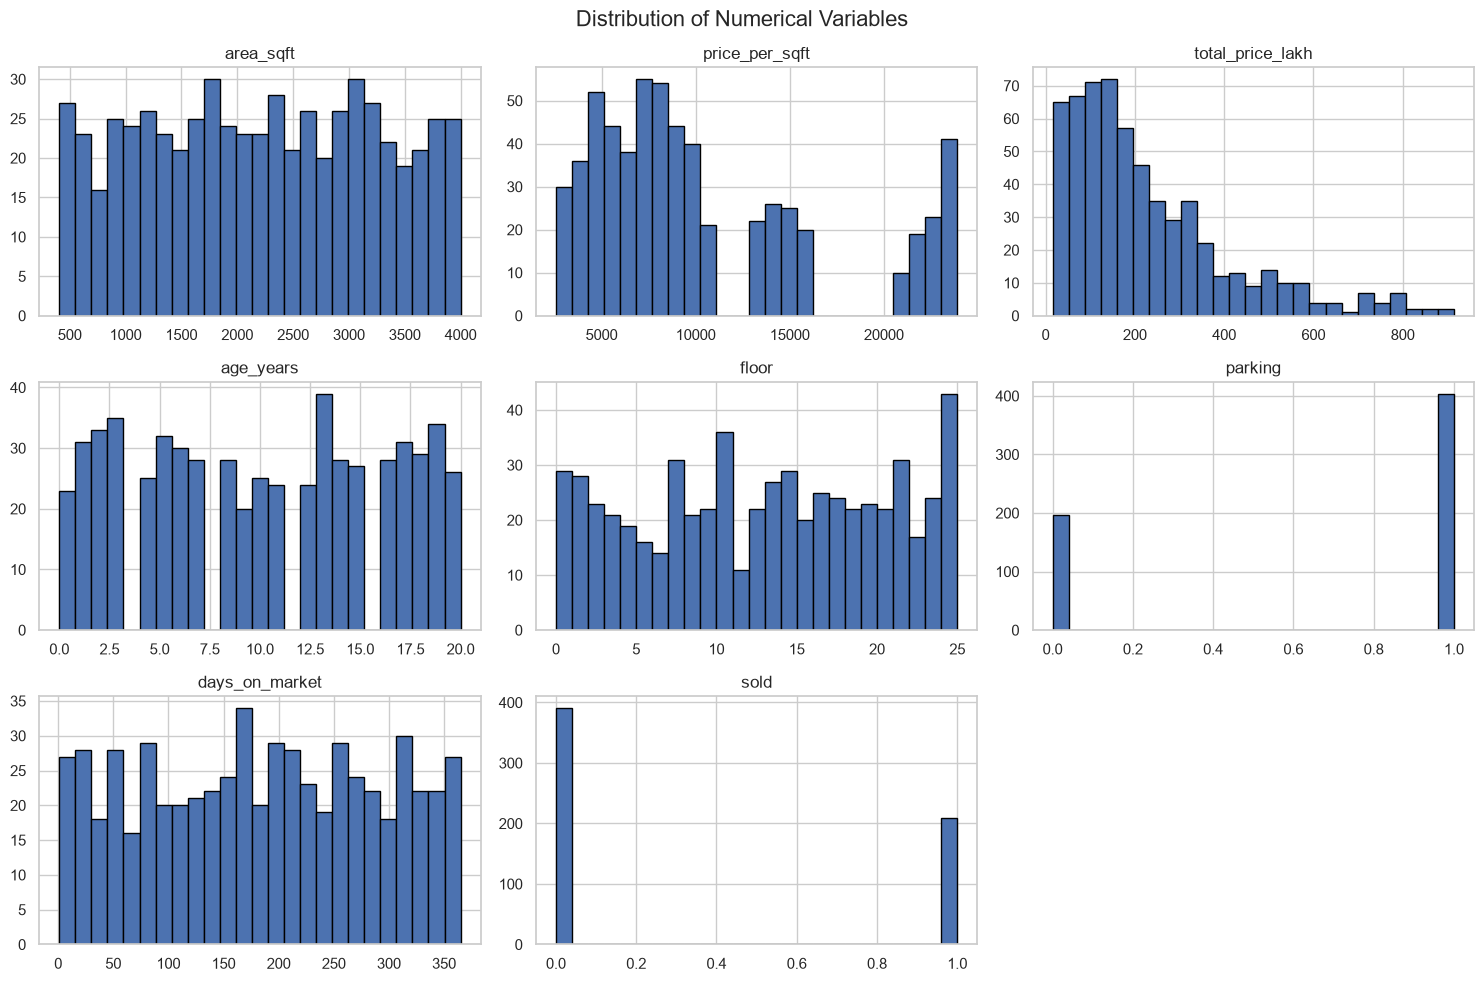

In [11]:
if len(numeric_cols) > 0:
    data[numeric_cols].hist(
        figsize=(15, 10),
        bins=25,
        edgecolor="black"
    )

    plt.suptitle("Distribution of Numerical Variables", fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns available.")

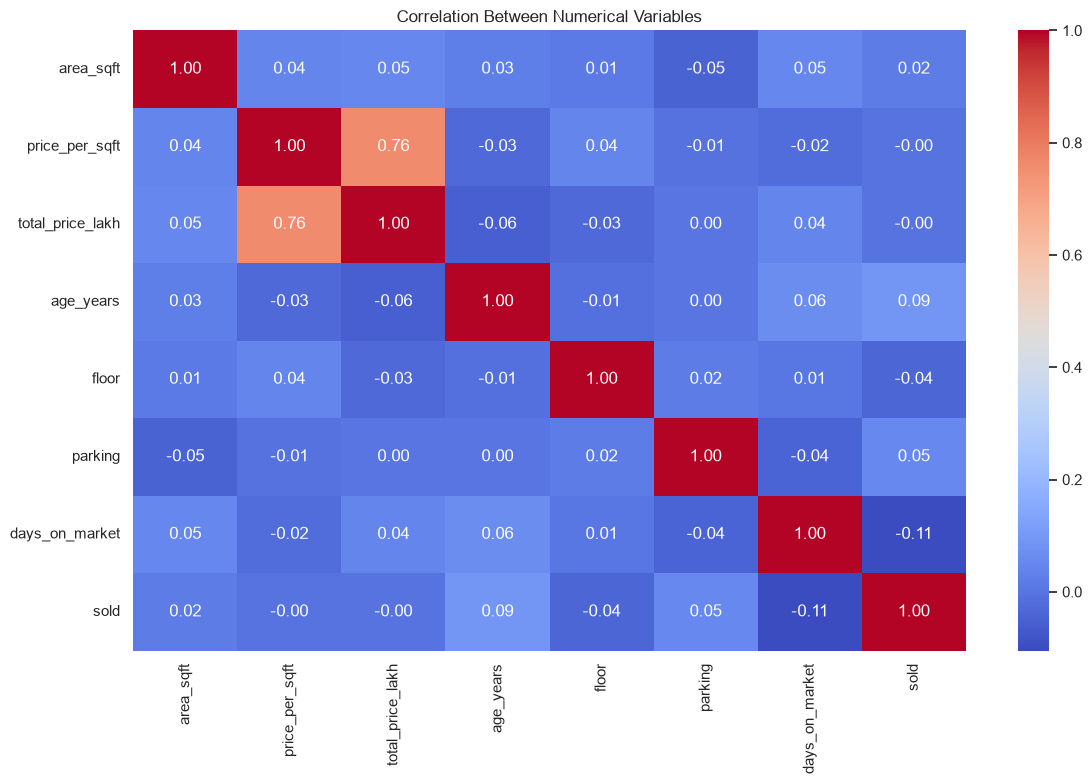

In [12]:
if len(numeric_cols) >= 2:
    plt.figure(figsize=(12, 8))

    sns.heatmap(
        data[numeric_cols].corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Between Numerical Variables")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical columns are required.")

In [13]:
categorical_cols = data.select_dtypes(include="object").columns

for col in categorical_cols[:5]:
    print(f"\nTop categories in {col}:")
    display(data[col].value_counts().head(10))




Top categories in listing_id:


listing_id
PROP-0001    1
PROP-0002    1
PROP-0003    1
PROP-0004    1
PROP-0005    1
PROP-0006    1
PROP-0007    1
PROP-0008    1
PROP-0009    1
PROP-0010    1
Name: count, dtype: int64


Top categories in city:


city
Chennai      93
Pune         79
Mumbai       76
Bengaluru    73
Hyderabad    72
Delhi NCR    71
Ahmedabad    69
Kolkata      67
Name: count, dtype: int64


Top categories in locality:


locality
KOL-Sector-21    8
PUN-Sector-21    8
MUM-Sector-20    8
BEN-Sector-6     7
BEN-Sector-1     7
DEL-Sector-24    7
AHM-Sector-26    6
CHE-Sector-30    6
BEN-Sector-23    6
CHE-Sector-18    5
Name: count, dtype: int64


Top categories in type:


type
4BHK          93
Villa         93
Commercial    90
1BHK          89
Plot          79
2BHK          79
3BHK          77
Name: count, dtype: int64


Top categories in furnished:


furnished
Fully          214
Unfurnished    198
Semi           188
Name: count, dtype: int64

In [14]:
os.makedirs("../outputs", exist_ok=True)

output_path = "../outputs/cleaned_indian_business_data.csv"

data.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)

Cleaned dataset saved to: ../outputs/cleaned_indian_business_data.csv


os.makedirs("../outputs", exist_ok=True)

output_path = "../outputs/cleaned_indian_business_data.csv"

data.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)

In [15]:
numeric_cols = data.select_dtypes(include=np.number).columns

outlier_summary = {}

for col in numeric_cols:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = data[(data[col] < lower) | (data[col] > upper)]

    outlier_summary[col] = len(outliers)

outlier_df = pd.DataFrame(
    list(outlier_summary.items()),
    columns=["Column", "Outlier_Count"]
)

display(outlier_df)

,Column,Outlier_Count
0,area_sqft,0
1,price_per_sqft,0
2,total_price_lakh,28
3,age_years,0
4,floor,0
5,parking,0
6,days_on_market,0
7,sold,0


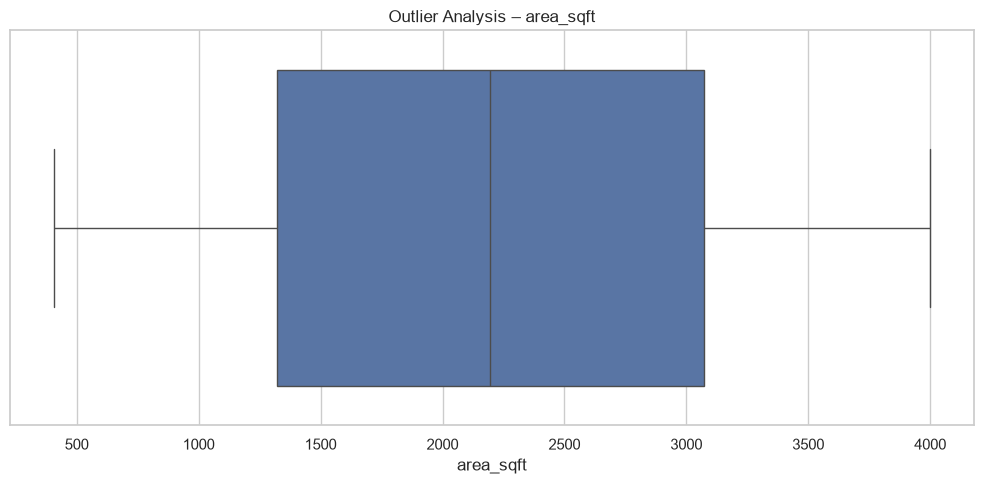

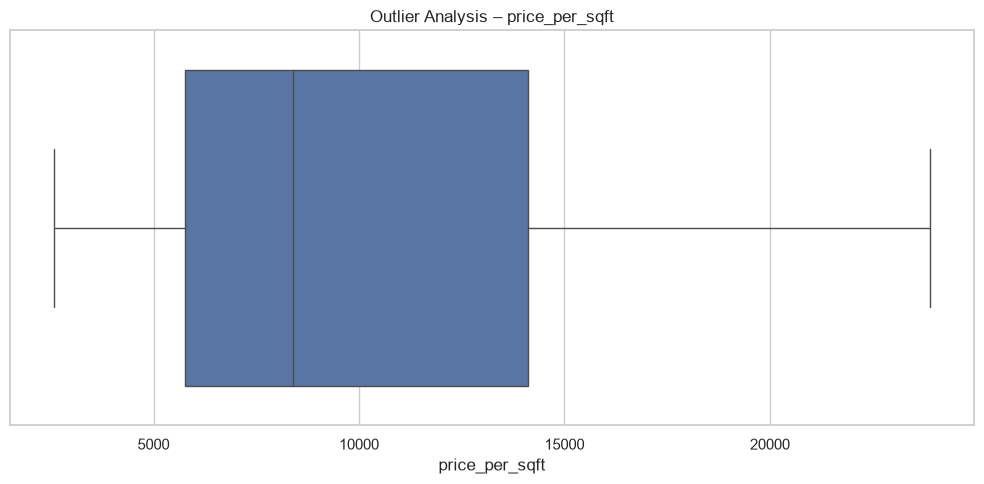

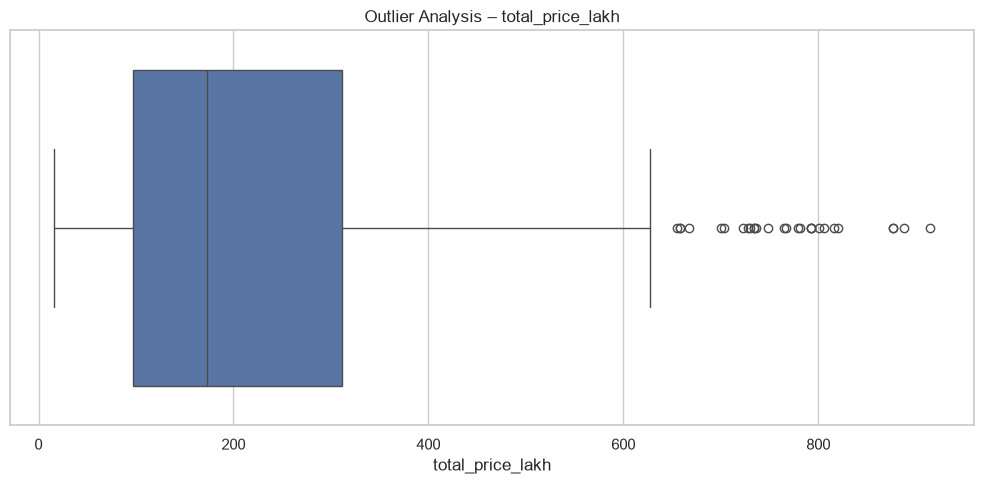

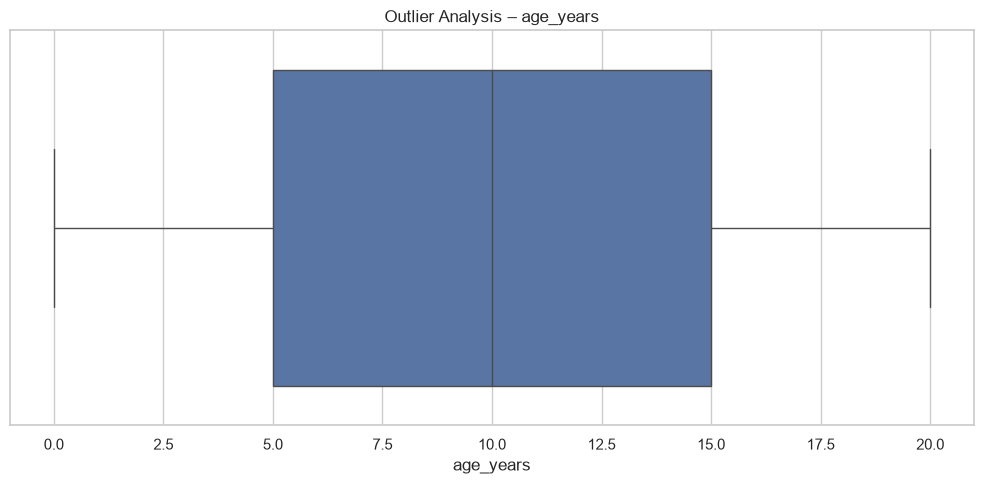

In [16]:
if len(numeric_cols) >= 1:
    for col in numeric_cols[:4]:
        plt.figure(figsize=(10, 5))

        sns.boxplot(x=data[col])

        plt.title(f"Outlier Analysis – {col}")
        plt.xlabel(col)

        plt.tight_layout()
        plt.show()

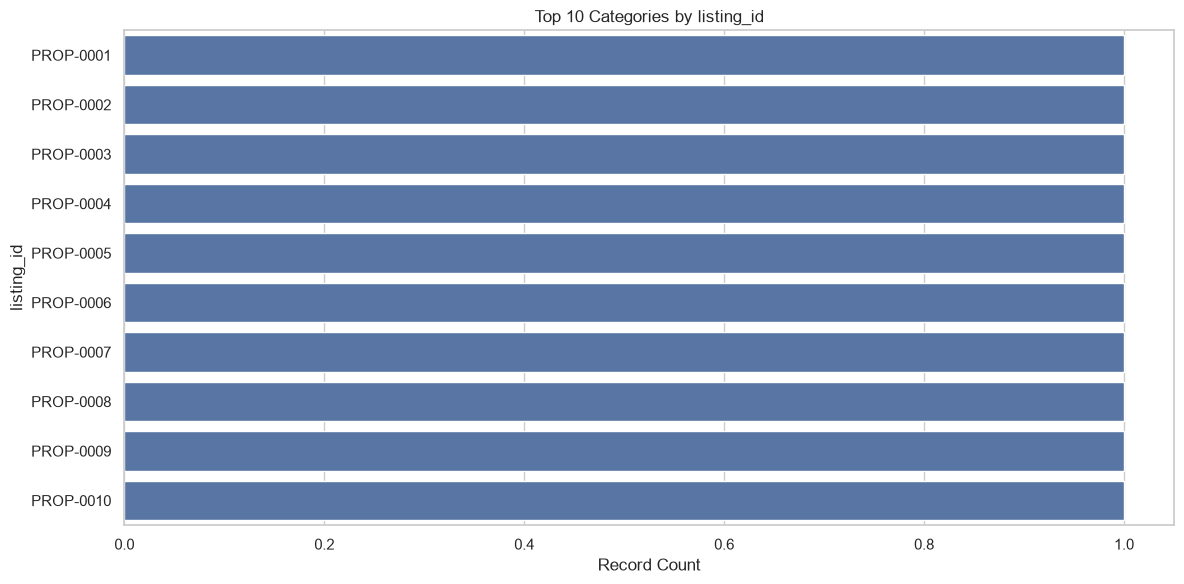

listing_id
PROP-0001    1
PROP-0002    1
PROP-0003    1
PROP-0004    1
PROP-0005    1
PROP-0006    1
PROP-0007    1
PROP-0008    1
PROP-0009    1
PROP-0010    1
Name: count, dtype: int64

In [17]:
categorical_cols = data.select_dtypes(include="object").columns

if len(categorical_cols) > 0:
    category_col = categorical_cols[0]

    top_categories = data[category_col].value_counts().head(10)

    plt.figure(figsize=(12, 6))

    sns.barplot(
        x=top_categories.values,
        y=top_categories.index
    )

    plt.title(f"Top 10 Categories by {category_col}")
    plt.xlabel("Record Count")
    plt.ylabel(category_col)

    plt.tight_layout()
    plt.show()

    display(top_categories)
else:
    print("No categorical columns available.")

In [18]:
print("=" * 60)
print("BUSINESS INSIGHT SUMMARY")
print("=" * 60)

print(f"Total records analyzed: {len(data):,}")
print(f"Total variables analyzed: {len(data.columns)}")

if len(numeric_cols) > 0:
    print("\nNumerical variable averages:")
    display(data[numeric_cols].mean().round(2))

if len(categorical_cols) > 0:
    for col in categorical_cols[:3]:
        print(f"\nMost common value in {col}:")
        print(data[col].value_counts().head(1))

BUSINESS INSIGHT SUMMARY
Total records analyzed: 600
Total variables analyzed: 15

Numerical variable averages:


area_sqft            2204.09
price_per_sqft      10444.07
total_price_lakh      229.10
age_years              10.02
floor                  12.46
parking                 0.67
days_on_market        183.70
sold                    0.35
dtype: float64


Most common value in listing_id:
listing_id
PROP-0001    1
Name: count, dtype: int64

Most common value in city:
city
Chennai    93
Name: count, dtype: int64

Most common value in locality:
locality
KOL-Sector-21    8
Name: count, dtype: int64


In [19]:
print("=" * 60)
print("BUSINESS INSIGHT SUMMARY")
print("=" * 60)

print(f"Total records analyzed: {len(data):,}")
print(f"Total variables analyzed: {len(data.columns)}")

if len(numeric_cols) > 0:
    print("\nNumerical variable averages:")
    display(data[numeric_cols].mean().round(2))

if len(categorical_cols) > 0:
    for col in categorical_cols[:3]:
        print(f"\nMost common value in {col}:")
        print(data[col].value_counts().head(1))

BUSINESS INSIGHT SUMMARY
Total records analyzed: 600
Total variables analyzed: 15

Numerical variable averages:


area_sqft            2204.09
price_per_sqft      10444.07
total_price_lakh      229.10
age_years              10.02
floor                  12.46
parking                 0.67
days_on_market        183.70
sold                    0.35
dtype: float64


Most common value in listing_id:
listing_id
PROP-0001    1
Name: count, dtype: int64

Most common value in city:
city
Chennai    93
Name: count, dtype: int64

Most common value in locality:
locality
KOL-Sector-21    8
Name: count, dtype: int64


\## 5. Data Storytelling: What – So What – Now What

### What?
The dataset was explored to understand its structure, distributions,
category patterns, missing values, and numerical relationships.

### So What?
The analysis highlights patterns and differences across the dataset.
These findings help identify areas that deserve business attention.

### Now What?
Business decisions should be guided by the strongest verified findings.
Further investigation should focus on unusual observations,
important category differences, and meaningful variable relationships.

In [20]:
data.to_csv("../outputs/cleaned_indian_business_data.csv", index=False)

print("Final cleaned dataset exported successfully.")

Final cleaned dataset exported successfully.


In [21]:
print("========== DATASET KPI SUMMARY ==========")

print(f"Total Records: {len(data):,}")
print(f"Total Columns: {len(data.columns)}")
print(f"Duplicate Records: {data.duplicated().sum()}")
print(f"Missing Values: {data.isnull().sum().sum()}")

numeric_cols = data.select_dtypes(include=np.number).columns

if len(numeric_cols) > 0:
    print("\nNumerical KPIs:")
    for col in numeric_cols:
        print(f"{col}: Mean = {data[col].mean():.2f}, Median = {data[col].median():.2f}")

========== DATASET KPI SUMMARY ==========
Total Records: 600
Total Columns: 15
Duplicate Records: 0
Missing Values: 0

Numerical KPIs:
area_sqft: Mean = 2204.09, Median = 2195.50
price_per_sqft: Mean = 10444.07, Median = 8401.00
total_price_lakh: Mean = 229.10, Median = 172.59
age_years: Mean = 10.02, Median = 10.00
floor: Mean = 12.46, Median = 13.00
parking: Mean = 0.67, Median = 1.00
days_on_market: Mean = 183.70, Median = 185.50
sold: Mean = 0.35, Median = 0.00


In [22]:
findings = []

for col in numeric_cols:
    findings.append({
        "Variable": col,
        "Mean": round(data[col].mean(), 2),
        "Median": round(data[col].median(), 2),
        "Minimum": round(data[col].min(), 2),
        "Maximum": round(data[col].max(), 2),
        "Standard Deviation": round(data[col].std(), 2)
    })

findings_df = pd.DataFrame(findings)

display(findings_df)

,Variable,Mean,Median,Minimum,Maximum,Standard Deviation
0,area_sqft,2204.09,2195.5,406.00,4000.00,1029.90
1,price_per_sqft,10444.07,8401.0,2574.00,23900.00,6214.61
2,total_price_lakh,229.10,172.6,15.71,914.71,183.75
3,age_years,10.02,10.0,0.00,20.00,6.13
4,floor,12.46,13.0,0.00,25.00,7.53
5,parking,0.67,1.0,0.00,1.00,0.47
6,days_on_market,183.70,185.5,1.00,365.00,105.18
7,sold,0.35,0.0,0.00,1.00,0.48


## 6. Business Recommendations

Based on the verified analysis:

1. **Focus on important categories:** Investigate categories with the highest
   representation and understand their business contribution.
2. **Investigate outliers:** Review unusual numerical values before making
   pricing, planning, or operational decisions.
3. **Monitor key metrics:** Track important numerical variables over time
   wherever date information is available.
4. **Improve data quality:** Maintain consistent formats and reduce missing
   and duplicate records.
5. **Use evidence-based decisions:** Validate analytical findings with
   additional business context before implementation.

In [23]:
os.makedirs("../outputs", exist_ok=True)

findings_df.to_csv("../outputs/business_findings.csv", index=False)
outlier_df.to_csv("../outputs/outlier_analysis.csv", index=False)
data.to_csv("../outputs/cleaned_indian_business_data.csv", index=False)

print("All analysis outputs exported successfully.")

All analysis outputs exported successfully.


os.makedirs("../outputs", exist_ok=True)

findings_df.to_csv("../outputs/business_findings.csv", index=False)
outlier_df.to_csv("../outputs/outlier_analysis.csv", index=False)
data.to_csv("../outputs/cleaned_indian_business_data.csv", index=False)

print("All analysis outputs exported successfully.")

In [24]:
print("NOTEBOOK COMPLETION CHECK")
print("-" * 40)

print("Dataset:", data.shape)
print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())

print("\nOutput files:")
for file in os.listdir("../outputs"):
    print("-", file)

print("\nW11D1 analysis execution completed.")

NOTEBOOK COMPLETION CHECK
----------------------------------------
Dataset: (600, 15)
Missing values: 0
Duplicate rows: 0

Output files:
- business_findings.csv
- cleaned_indian_business_data.csv
- outlier_analysis.csv

W11D1 analysis execution completed.
